# Warm up
Let's start with some warm up exercises to get you familiar with the database and do some SQL querying.
Make sure to have downloaded the NBA dataset form Kaggle as described in the README.

In [1]:
import sqlite3 as sql
import pandas as pd
from pathlib import Path

## TODO: Use pathlib to get the path to the data directory. Path(__file__) won't work in a Jupyter notebook.
DATA_PATH = Path.cwd() / 'data' / 'nba.sqlite'

## Create a SQLite connection and run some SQL queries

In [7]:
con = sql.connect(DATA_PATH)  # connect to the database
query = 'SELECT * FROM game LIMIT 10'  # write a query that selects the first 10 rows from the game table
top_10_game = pd.read_sql(query, con)  # read the query into a pandas dataframe
top_10_game.head()  # print the dataframe

,season_id,team_id_home,team_abbreviation_home,team_name_home,game_id,game_date,matchup_home,wl_home,min,fgm_home,...,reb_away,ast_away,stl_away,blk_away,tov_away,pf_away,pts_away,plus_minus_away,video_available_away,season_type
0,21946,1610610035,HUS,Toronto Huskies,0024600001,1946-11-01 00:00:00,HUS vs. NYK,L,0,25.0,...,None,None,None,None,None,NaN,68.0,2,0,Regular Season
1,21946,1610610034,BOM,St. Louis Bombers,0024600003,1946-11-02 00:00:00,BOM vs. PIT,W,0,20.0,...,None,None,None,None,None,25.0,51.0,-5,0,Regular Season
2,21946,1610610032,PRO,Providence Steamrollers,0024600002,1946-11-02 00:00:00,PRO vs. BOS,W,0,21.0,...,None,None,None,None,None,NaN,53.0,-6,0,Regular Season
3,21946,1610610025,CHS,Chicago Stags,0024600004,1946-11-02 00:00:00,CHS vs. NYK,W,0,21.0,...,None,None,None,None,None,22.0,47.0,-16,0,Regular Season
4,21946,1610610028,DEF,Detroit Falcons,0024600005,1946-11-02 00:00:00,DEF vs. WAS,L,0,10.0,...,None,None,None,None,None,NaN,50.0,17,0,Regular Season


In [12]:
# let's look at the schema of the database
# TODO: sqlite_master is the name of the table you want to inspeact: Replace TABLE_NAME with the name of the table you want to inspect
query = """
    SELECT *
    FROM sqlite_master
"""
#query = "PRAGMA table_info(game)"

pd.read_sql(query, con).sort_values('name')

,type,name,tbl_name,rootpage,sql
10,table,common_player_info,common_player_info,4314,"CREATE TABLE ""common_player_info"" (\n""person_i..."
13,table,draft_combine_stats,draft_combine_stats,4313,"CREATE TABLE ""draft_combine_stats"" (\n""season""..."
14,table,draft_history,draft_history,4318,"CREATE TABLE ""draft_history"" (\n""person_id"" TE..."
0,table,game,game,52,"CREATE TABLE ""game"" (\n""season_id"" TEXT,\n ""t..."
5,table,game_info,game_info,9457,"CREATE TABLE ""game_info"" (\n""game_id"" TEXT,\n ..."
1,table,game_summary,game_summary,4564,"CREATE TABLE ""game_summary"" (\n""game_date_est""..."
4,table,inactive_players,inactive_players,7443,"CREATE TABLE ""inactive_players"" (\n""game_id"" T..."
6,table,line_score,line_score,10084,"CREATE TABLE ""line_score"" (\n""game_date_est"" T..."
3,table,officials,officials,6747,"CREATE TABLE ""officials"" (\n""game_id"" TEXT,\n ..."
2,table,other_stats,other_stats,6025,"CREATE TABLE ""other_stats"" (\n""game_id"" TEXT,\..."


In [16]:
# let's see all the tables we have in the database
# TODO: Filter for tables only
query = """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
"""
pd.read_sql(query, con)

,name
0,game
1,game_summary
2,other_stats
3,officials
4,inactive_players
5,game_info
6,line_score
7,play_by_play
8,player
9,team


In [19]:
# let's have a look at the columns in the game table
query = """
    PRAGMA table_info(draft_combine_stats)
"""
pd.read_sql(query, con)

,cid,name,type,notnull,dflt_value,pk
0,0,season,TEXT,0,None,0
1,1,player_id,TEXT,0,None,0
2,2,first_name,TEXT,0,None,0
3,3,last_name,TEXT,0,None,0
4,4,player_name,TEXT,0,None,0
5,5,position,TEXT,0,None,0
6,6,height_wo_shoes,REAL,0,None,0
7,7,height_wo_shoes_ft_in,TEXT,0,None,0
8,8,height_w_shoes,REAL,0,None,0
9,9,height_w_shoes_ft_in,TEXT,0,None,0


In [24]:
# let's find the earliest recorded game
query = """
    SELECT game_date
    FROM game
    ORDER BY game_date
    LIMIT 1
"""

print(pd.read_sql(query, con))

# let's find the latest recorded game
query = """
    SELECT game_date
    FROM game
    ORDER BY game_date DESC
    LIMIT 1
"""

print(pd.read_sql(query, con))


             game_date
0  1946-11-01 00:00:00
             game_date
0  2023-06-12 00:00:00


In [ ]:
# TODO: Find four interesting facts about the data and write a query to find the answer

"""
Fact 1: When was the longest period without a game?

1. game_dates - becomes a column contain each unique game date
2. gaps - becomes two columns [the previous game date and the next game date]
3. gap_lengths - casts the dates into numeric day values, does the difference 
                 and expresses it as a whole number
4. return the five longest gaps
"""

query = """
WITH game_dates AS (
    SELECT DISTINCT DATE(game_date) AS game_day
    FROM game
    WHERE game_date IS NOT NULL
),
gaps AS (
    SELECT
        LAG(game_day) OVER (ORDER BY game_day) AS previous_game_date,
        game_day AS next_game_date
    FROM game_dates
),
gap_lengths AS (
    SELECT *,
        CAST(
            JULIANDAY(next_game_date) - JULIANDAY(previous_game_date)
            AS INTEGER
        ) - 1 AS days_without_games
    FROM gaps
    WHERE previous_game_date IS NOT NULL
)
SELECT *
FROM gap_lengths
ORDER BY days_without_games DESC, previous_game_date
LIMIT 5
"""
pd.read_sql(query, con)



,previous_game_date,next_game_date,days_without_games
0,1961-01-17,1962-01-16,363
1,1960-04-09,1961-01-17,282
2,1966-04-28,1967-01-10,256
3,1975-05-25,1976-02-03,253
4,1976-06-06,1977-02-13,251


In [27]:
#which date had the most games in each year?

query = """
WITH daily_counts AS (
    SELECT
        STRFTIME('%Y', game_date) AS year,
        DATE(game_date) AS game_day,
        COUNT(DISTINCT game_id) AS number_of_games
    FROM game
    WHERE game_date IS NOT NULL
    GROUP BY year, game_day
),
ranked_dates AS (
    SELECT *,
        DENSE_RANK() OVER (
            PARTITION BY year
            ORDER BY number_of_games DESC
        ) AS position
    FROM daily_counts
)
SELECT year, game_day, number_of_games
FROM ranked_dates
WHERE position = 1
ORDER BY year, game_day
"""
pd.read_sql(query, con)

,year,game_day,number_of_games
0,1946,1946-11-16,5
1,1946,1946-12-07,5
2,1947,1947-02-23,5
3,1948,1948-11-13,6
4,1948,1948-12-04,6
...,...,...,...
495,2020,2020-01-20,14
496,2021,2021-05-16,15
497,2022,2022-04-10,15
498,2022,2022-11-07,15


In [ ]:
#which five years had the most games?

query = """
WITH yearly_counts AS (
    SELECT
        STRFTIME('%Y', game_date) AS year,
        COUNT(DISTINCT game_id) AS number_of_games
    FROM game
    WHERE game_date IS NOT NULL
    GROUP BY year
)
SELECT *
FROM yearly_counts
ORDER BY number_of_games DESC, year
LIMIT 5
"""
pd.read_sql(query, con)

,year,number_of_games
0,2021,1692
1,2014,1453
2,2008,1443
3,2010,1441
4,2009,1435


In [ ]:
# Average games on every month-day, including zero-game days.
query = """
WITH RECURSIVE
date_bounds AS (
    SELECT MIN(DATE(game_date)) AS first_day,
           MAX(DATE(game_date)) AS last_day
    FROM game
),
calendar(game_day) AS (
    SELECT first_day FROM date_bounds WHERE first_day IS NOT NULL
    UNION ALL
    SELECT DATE(game_day, '+1 day')
    FROM calendar, date_bounds
    WHERE game_day < last_day
),
daily_counts AS (
    SELECT
        DATE(game_date) AS game_day,
        COUNT(DISTINCT game_id) AS number_of_games
    FROM game
    WHERE game_date IS NOT NULL
    GROUP BY DATE(game_date)
)
SELECT
    STRFTIME('%m-%d', calendar.game_day) AS month_day,
    AVG(COALESCE(daily_counts.number_of_games, 0)) AS average_games,
    COUNT(*) AS years_observed
FROM calendar
LEFT JOIN daily_counts ON calendar.game_day = daily_counts.game_day
GROUP BY month_day
ORDER BY month_day
"""
pd.read_sql(query, con)


,month_day,average_games,years_observed
0,01-01,2.350649,77
1,01-02,5.532468,77
2,01-03,4.558442,77
3,01-04,5.051948,77
4,01-05,4.857143,77
...,...,...,...
361,12-27,4.779221,77
362,12-28,4.974026,77
363,12-29,4.792208,77
364,12-30,5.844156,77


## Visualize the four query results

The second chart shows the busiest day's game count per year; tied dates remain in `results[2]`. The gaps reflect records in this dataset. Chart 4 averages recorded games for each month-day over dates between the first and last recorded games, including zero-game days. February 29 uses only leap years. Dates outside that range are excluded, so partial boundary years contribute only observed dates. Missing records within the range count as zero games.


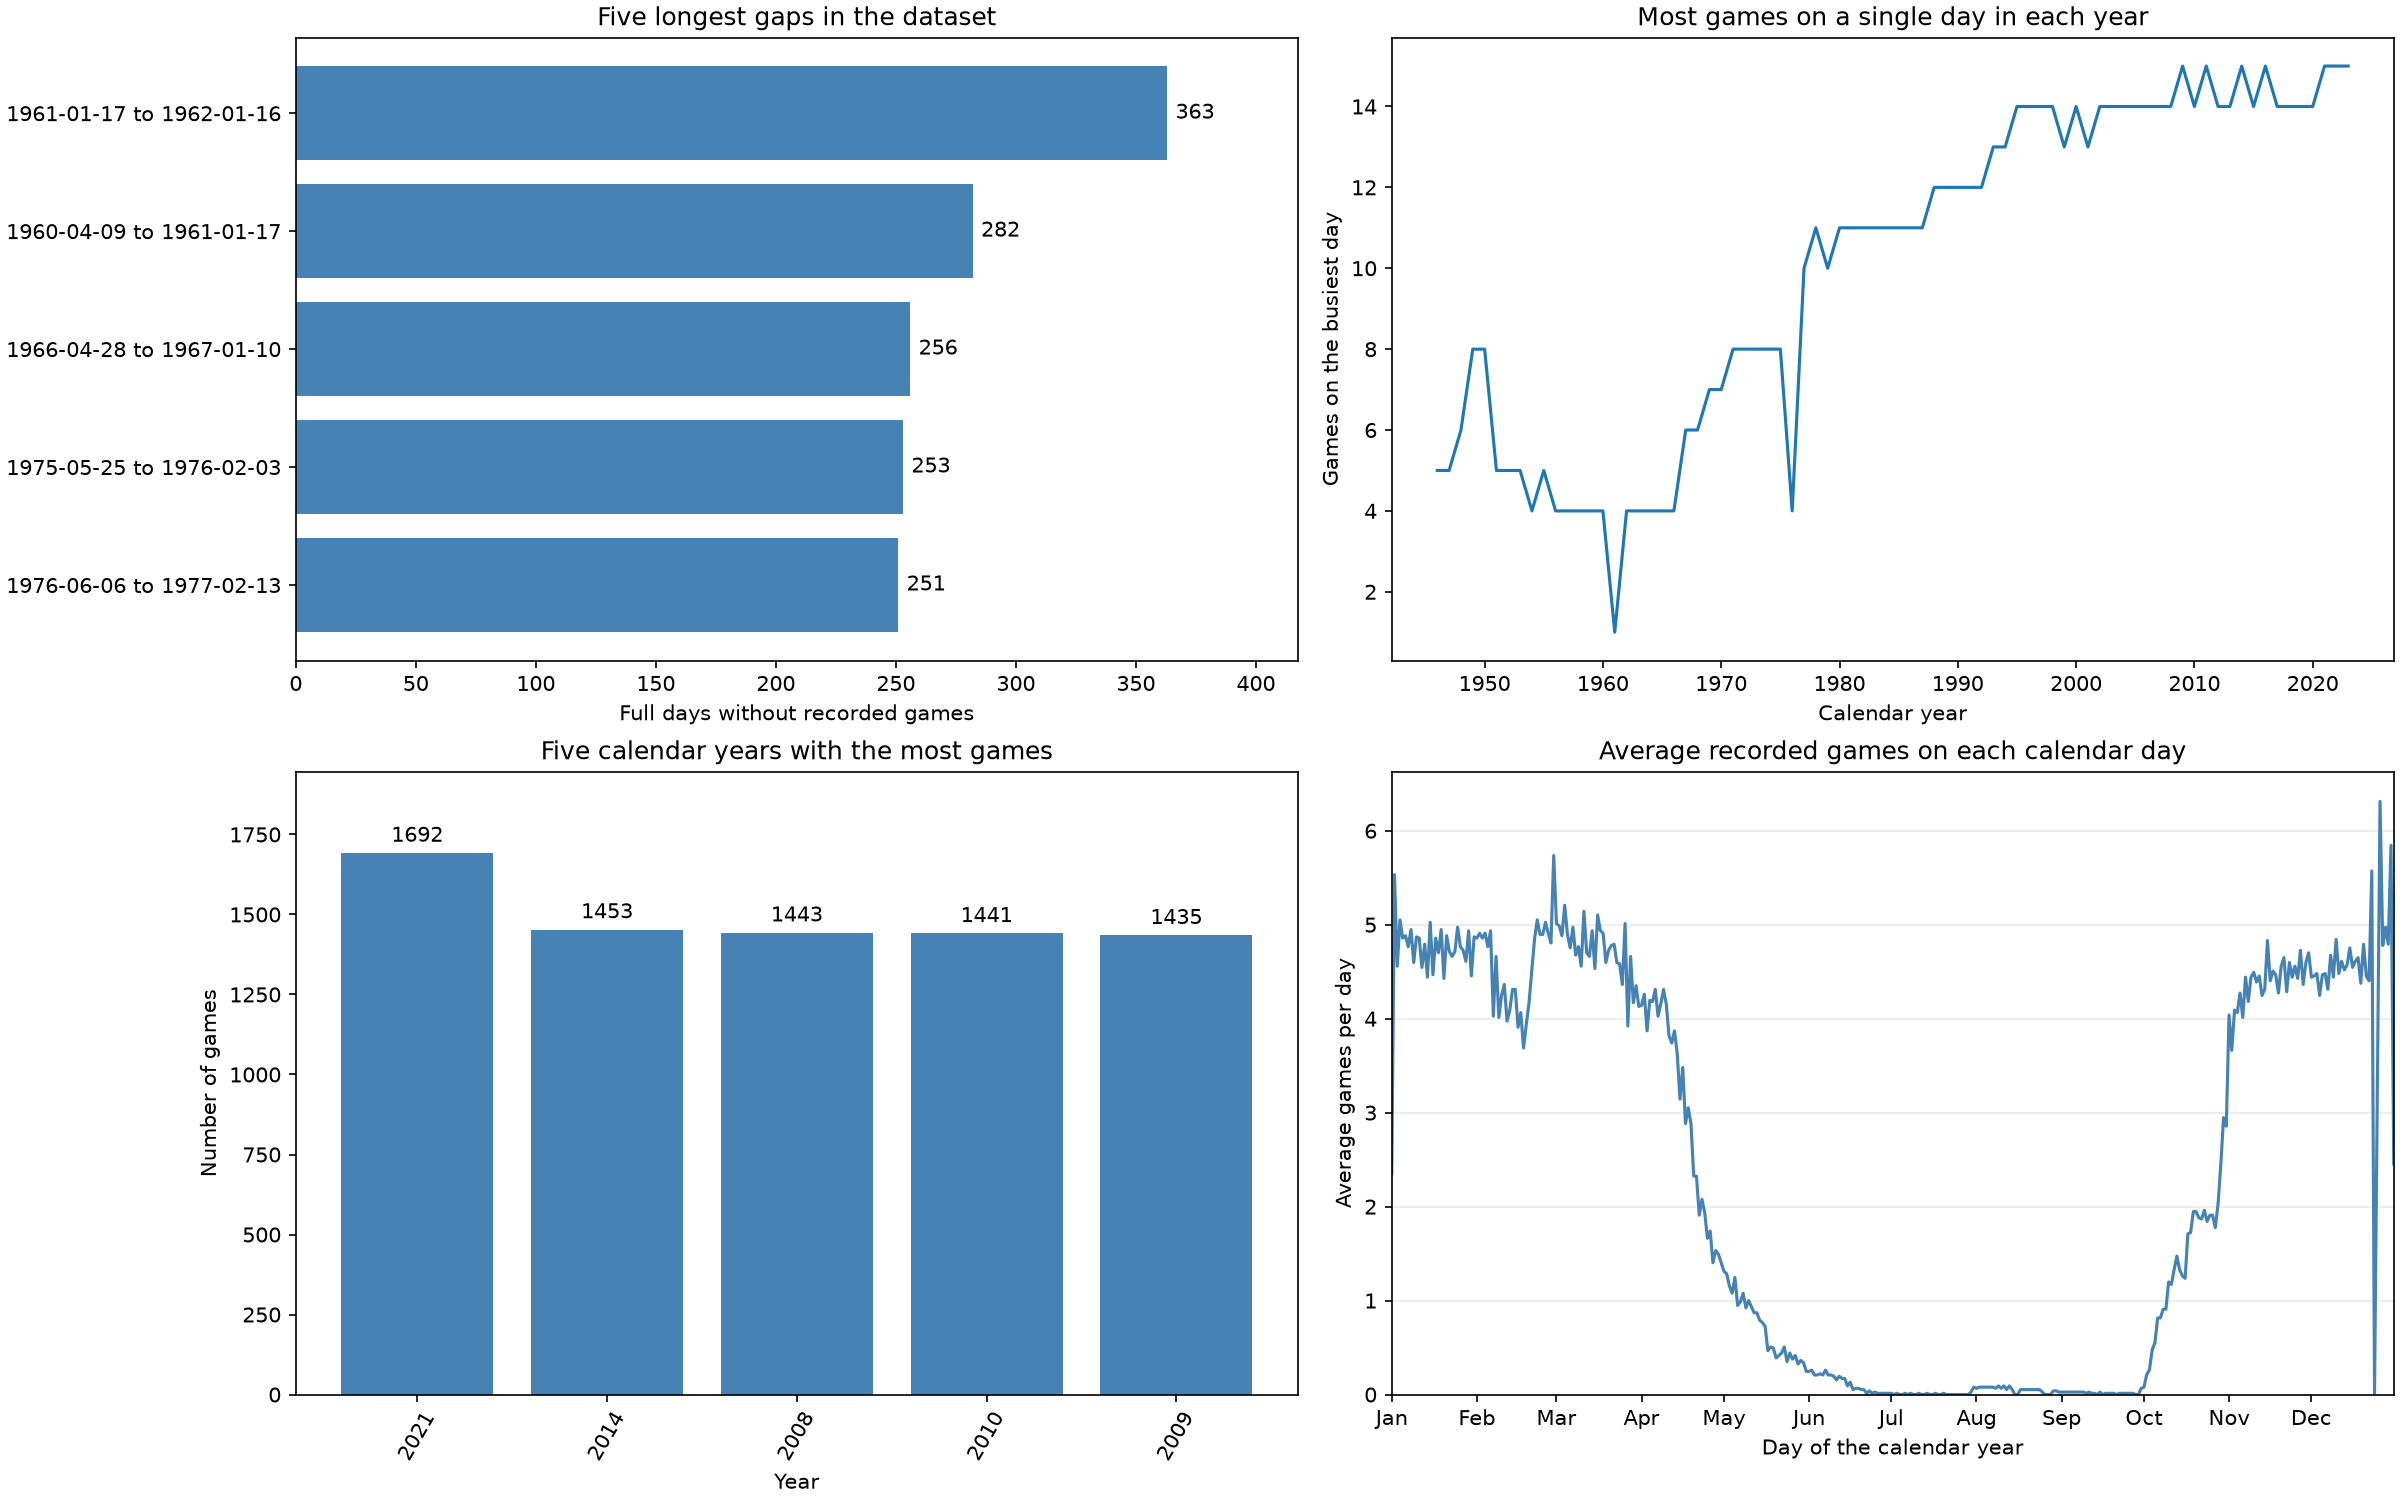

In [ ]:
# Run the four queries and plot their results.
import matplotlib.pyplot as plt
from nba.wrangling import query_1, query_2, query_3, query_4
from nba.visualization import plot_results

queries = {1: query_1, 2: query_2, 3: query_3, 4: query_4}
results = {
    number: pd.read_sql(query, con)
    for number, query in queries.items()
}

fig, axes = plot_results(results)

# Save a copy as well as displaying the charts below.
chart_path = Path("figures") / "nba_facts.png"
chart_path.parent.mkdir(exist_ok=True)
fig.savefig(chart_path, dpi=150)
plt.show()
